### Notebook for developing a spectrum generator for $LaBr_3(Ce)$ detectors to be used in machine-learning
Resources used to pick parameters
- https://www.researchgate.net/publication/338999700_Energy_Resolution_and_Efficiency_Calibration_of_a_LaBr3Ce_Scintillator

##### Features that need to be included in the generated spectera
- [ ] Efficiency
- [ ] Resolution
- [ ] Poisson noise
- [ ] Compton continuum 

Per peak:
- [ ] Peak energy
- [ ] Compton edge / backscatter peak
- [ ] Pair production
- [ ] Single escape
- [ ] Double escape

### Deciding pair production intensity stuff
NIST XCOM resource: https://physics.nist.gov/PhysRefData/Xcom/html/xcom1.html
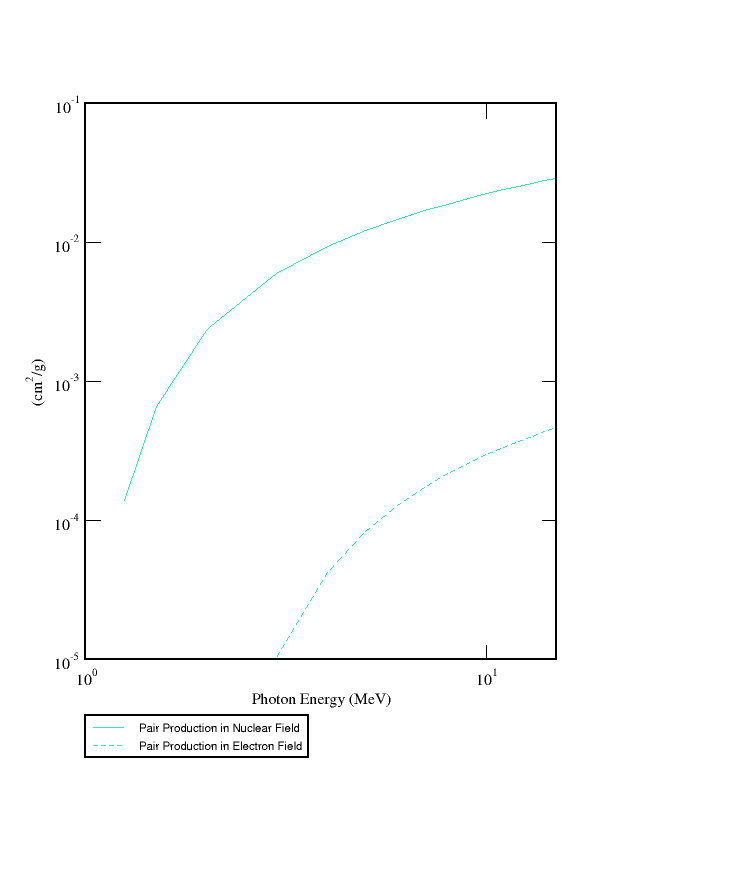

### Details for OSCAR
https://www.sciencedirect.com/science/article/pii/S0168900220310755
30 Large volume BriLanCe scintiallting crystals
Diameter: 3.5 inches
Length: 8 inches
Distance from target to detector faces = 16.3 cm

Density: 5.08 g/cm³ taken from https://luxiumsolutions.com/sites/default/files/2021-06/LaBr-Performance-Summary-2021.pdf page 11

NIST XCOM provides mass attenuation coeffs $\mu/\rho$ in cm²/g for LaBr3 with the file [text](<XCOM_ Photon Cross Sections Data for LaBr3.html>). 
We ignore the Ce mixture, as it is similar Z. Should be fine for our case.


Assuming isotropic source, so that mean chord length is $\bar{X}= 4V/S$ from https://www.epj-n.org/articles/epjn/full_html/2018/01/epjn170083/epjn170083.html


#### Outline of project

proj3/
  detector.py        class LaBr3Detector
                       - geometry, density, XCOM tables (loaded once)
                       - linearAttenuation(keVEnergy, process)
                       - fwhm(keVEnergy), efficiency(keVEnergy)
                       - sampleFirstInteraction(counts, mu, randomGenerator)
  spectrum_parts.py  pure functions, no randomness:
                       gaussianPeak, comptonContinuumShape, comptonEdgeEnergy,
                       escapePeakEnergies, smoothBackground, energyToChannel
  simulate.py        simulateSpectrum(detector, keVGrid, randomGenerator)
                       -> (counts, peakChannels)
                       draws lines, amplitudes, calibration, then a single Poisson draw
  matching.py        matchPeaks(predicted, true, tolerance) -> TP/FP/FN, precision/recall/F1
  models/            logistic regression, tree ensemble, 1D CNN, find_peaks baseline
  tests/             known-answer tests for each piece
  spectrum_generator.ipynb   imports from the above; plots, exploration, figures

coefficients: (30, 4) | fit range: 500.0 - 11000.0 keV


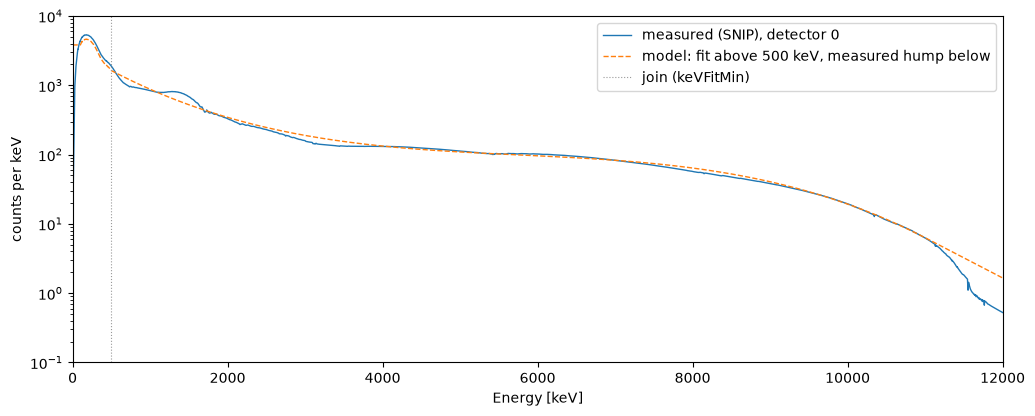

In [4]:
# Fit the background model to the 28Si SNIP backgrounds and compare it with the measured background
# LLM usage: Level 2 (Snippet); an LLM wrote this cell.
import numpy as np
import matplotlib.pyplot as plt
from data_reader import DEFAULT_BACKGROUND_PATH
from spectrum_parts import fitBackgroundCoefficients, lowEnergyBackgroundRatios, backgroundShape

coefficients, keVFitMin, keVFitMax = fitBackgroundCoefficients()   # (30 detectors, 4), fit range in keV
keVLowGrid, lowEnergyRatios = lowEnergyBackgroundRatios()          # measured shape below keVFitMin
print("coefficients:", coefficients.shape, "| fit range:", keVFitMin, "-", keVFitMax, "keV")

backgrounds = np.load(DEFAULT_BACKGROUND_PATH)
keVEnergy = backgrounds["keVBinCentres"]
detector = 0
measuredBackground = backgrounds["background"][detector]

modelShape = backgroundShape(keVEnergy, coefficients[detector], keVFitMin, keVFitMax,
                             lowEnergyRatio=lowEnergyRatios[detector], keVLowGrid=keVLowGrid, humpScale=1.0)
modelBackground = modelShape * measuredBackground.sum()   # the shape sums to 1; scale to the measured counts

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(keVEnergy, measuredBackground, lw=1, label=f"measured (SNIP), detector {detector}")
ax.plot(keVEnergy, modelBackground, lw=1, ls="--", label="model: fit above 500 keV, measured hump below")
ax.axvline(keVFitMin, color="0.6", lw=0.8, ls=":", label="join (keVFitMin)")
ax.set_yscale("log")
ax.set_xlim(0, 12000)
ax.set_ylim(1e-1, 1e4)
ax.set_xlabel("Energy [keV]")
ax.set_ylabel("counts per keV")
ax.legend()
plt.show()

The background is based on the 28Si data. Unless needed, we should withold this dataset to avoid that the simulator leaks into our ML models. 

### Making and reading the simulated datasets

**Before generating:** set the ranges in `DEFAULT_SETTINGS` at the top of `simulate.py`, in particular `numberOfChannels` and `keVPerChannelRange` (they must match how the real 65536-channel spectra are rebinned for the network) and `totalCountsRange`. The inputs must exist:
- `data/reference/escape_ratios_LaBr3.csv` (from `python photon_transport_mc.py`)
- `data/backgrounds/backgrounds_<run>.npz` (from `python extract_backgrounds.py data/measured/<run>.root`)

**Generate** (from a terminal in `proj3/`, about 0.08 s per spectrum):
```
~/machinelearning/bin/python simulate.py                       # 2000 training, 500 validation, 500 test
~/machinelearning/bin/python simulate.py --training 0          # only validation and test
~/machinelearning/bin/python simulate.py --training 10000 --seed 2026
```
This writes `data/datasets/training.npz`, `validation.npz` and `test.npz`. The splits use `np.random.SeedSequence(seed).spawn(3)`, so the same seed always gives the same data. The "test" split is synthetic and only for development; the final test is the hand-labelled real spectra.

**Contents of each file** (N spectra, up to `maxPeaksPerSpectrum` labels each, padded with NaN, or -1 for `labelPeakType`):
- `counts` (N, channels): the simulated spectra, the network input
- `numberOfLabels` (N,): number of real labels per spectrum
- `labelChannel` (N, maxPeaks): peak positions as fractional channels (channel i covers [i, i+1))
- `labelPeakType`, `labelKeVEnergy`, `labelArea`, `labelFwhmChannels`, `labelSignificance`
- per-spectrum parameters: `totalCounts`, `backgroundFraction`, `keVPerChannel`, `keVOffset`, `fwhmScale`, ...
- `settingsJson`, `peakTypesJson`, `seedInfo`: how the file was made

The next cell loads a dataset and plots one spectrum with its labels.

made with np.random.SeedSequence(2026).spawn(3)[1] | spectra, channels: (500, 8192)


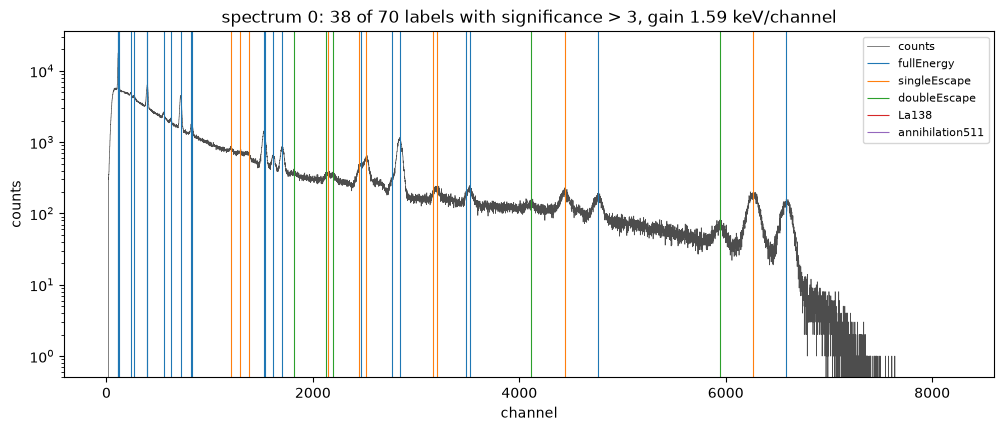

In [ ]:
# Load a simulated dataset and look at one spectrum with its labels
# LLM usage: Level 2 (Snippet); an LLM wrote this cell.
import json
import numpy as np
import matplotlib.pyplot as plt
from data_reader import DATASETS_DIR

dataset = np.load(DATASETS_DIR / "validation.npz")
peakTypes = json.loads(str(dataset["peakTypesJson"]))   # e.g. {"fullEnergy": 0, ...}
peakTypeNames = {code: name for name, code in peakTypes.items()}
print("made with", dataset["seedInfo"], "| spectra, channels:", dataset["counts"].shape)

spectrumIndex = 0
numberOfLabels = dataset["numberOfLabels"][spectrumIndex]
counts = dataset["counts"][spectrumIndex]
labelChannels = dataset["labelChannel"][spectrumIndex, :numberOfLabels]   # drop the NaN padding
labelTypes = dataset["labelPeakType"][spectrumIndex, :numberOfLabels]
labelSignificance = dataset["labelSignificance"][spectrumIndex, :numberOfLabels]

# Optional: only keep peaks that are visible above the background
isVisible = labelSignificance > 3

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.step(np.arange(counts.size), counts, where="post", lw=0.5, color="0.3", label="counts")
for code in np.unique(labelTypes):
    selected = (labelTypes == code) & isVisible
    ax.vlines(labelChannels[selected], 0.5, counts.max() * 2, colors=f"C{code}", lw=0.8,
              label=peakTypeNames[code])
ax.set_yscale("log")
ax.set_ylim(0.5, counts.max() * 2)
ax.set_xlabel("channel")
ax.set_ylabel("counts")
ax.set_title(f"spectrum {spectrumIndex}: {isVisible.sum()} of {numberOfLabels} labels with significance > 3, "
             f"gain {dataset['keVPerChannel'][spectrumIndex]:.2f} keV/channel")
ax.legend(fontsize=8)
plt.show()

### The labels in a simulated dataset

Every spectrum has a variable number of labelled peaks. The label arrays have shape (N spectra, `maxPeaksPerSpectrum`); for spectrum `i` only the first `numberOfLabels[i]` entries are real, the rest is padding (NaN, or -1 for `labelPeakType`). One entry describes one peak, and the same index refers to the same peak in every label array.

Peaks that are labelled: full-energy peaks, their single- and double-escape peaks, the La-138 peak (~1470 keV) and the 511 keV annihilation peak. **Not** labelled: Compton edges and continua, the low-energy hump and the background, since these are what the network should learn to ignore. Peaks outside the channel range, or where the threshold / upper cut-off removes more than half of the counts, are dropped.

| Label | Unit | Meaning |
|---|---|---|
| `labelChannel` | channels (fractional) | Position of the peak centre. Channel *i* covers [*i*, *i*+1), so the centre of channel *i* is *i*+0.5. This is the main target for the network. |
| `labelPeakType` | integer code | What kind of peak it is; the codes are in `peakTypesJson`: 0 full energy, 1 single escape, 2 double escape, 3 La-138, 4 annihilation (511 keV). Lets you evaluate e.g. recall on escape peaks separately. |
| `labelKeVEnergy` | keV | The true energy of the peak. Not available for real spectra (they are uncalibrated); useful for analysis, e.g. recall versus energy. |
| `labelArea` | counts | Expected number of counts in the peak (before Poisson noise), after the threshold and cut-off. |
| `labelFwhmChannels` | channels | Width (FWHM) of the peak in channels, with the local gain at the peak. Useful for the matching tolerance (a prediction within ~½ FWHM counts as correct) and for building window-shaped targets. |
| `labelSignificance` | dimensionless | How clearly the peak stands out above everything under it; see below. |

**`labelSignificance`.** It estimates how many standard deviations of Poisson noise the peak sticks out:

$$\text{significance} = \frac{0.98\,A}{\sqrt{N_{\pm 1\,\mathrm{FWHM}}}}$$

where $A$ is the peak area (`labelArea`), $0.98\,A$ is the part of a Gaussian peak within ±1 FWHM of its centre, and $N_{\pm 1\,\mathrm{FWHM}}$ is the expected number of **all** counts in that window (the peak itself, background, Compton continua and any neighbouring peaks). Since Poisson noise on $N$ counts is $\sqrt{N}$, the ratio says how many noise standard deviations the peak counts correspond to; it is the familiar $S/\sqrt{S+B}$.
- Roughly: below ~1 the peak is invisible in the noise, around 3 it is just visible, above ~5 it is clear.
- It is computed from the expected (noise-free) spectrum, so it describes how detectable a peak *should* be, independent of the particular Poisson draw.
- It is not used by the simulator itself. It is stored so you can decide later which peaks count as "real" targets, e.g. `labelSignificance > 3`, without regenerating data. This matters because hand-labelled real spectra only contain peaks a person can see, and the network should not be punished for missing a peak that is buried in noise.

**Per-spectrum parameters** (shape (N,), not labels, but useful for analysing results, e.g. recall versus total counts): `totalCounts`, `backgroundFraction`, `keVOffset`, `keVPerChannel`, `keVPerChannel2` (the random energy-to-channel response), `fwhmScale`, `numberOfRandomPeaks`, `backgroundDetectorIndex`, `humpScale`, `keVThreshold`, `keVUpperCutoff`.

### Comparing with datasets
with `compare_simulation.py`, we pick out the approximate areas of each peak and the amount of background present, to then run the same targets but with the simulator to see how well we match our actual data. Here the simulated background shape remains the same and originates from 28Si. To get comparison plots, run `compare_simulation.py all`
![alt text](figures/compare_simulation_Si28_detector0.png)
![alt text](figures/compare_simulation_Pd106_detector0.png)
![alt text](figures/compare_simulation_Al27_detector0.png)

We see that the spectrum generator manages to reproduce major features on the spectrograms, but that there are features it fails to include. We hope that this will be sufficient to train the models either way